# 02. Data Cleaning & Preprocessing — UCI Online Retail II

**Project:** E-Commerce Customer Analytics  
**Objective:** Apply transparent, rule-based data cleaning to the raw combined UCI Online Retail II dataset (`dataset/Ecommerce.csv`), validate every transformation, preserve the original CSV untouched, and save well-documented analytical datasets under `dataset/processed/`.

> **Key Business Rules Enforced:**
> - Never modify or overwrite the raw CSV (`dataset/Ecommerce.csv`).
> - Do not automatically delete all negative quantities—distinguish customer returns/cancellations (`C`-invoices) from warehouse write-offs and bad-debt ledger adjustments (`A`-invoices).
> - Never invent missing `Customer ID` or `Description` values; keep missing `customer_id` rows transparently flagged for transaction-level reporting while enabling strict `has_customer_id == True` filtering for customer-level ML/RFM modeling.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.paths import get_primary_dataset_path
from src.data.audit import load_raw_transactions
from src.data.cleaning import (
    INTERNAL_NON_COMMERCIAL_CODES,
    SERVICE_OR_FEE_CODES,
    clean_retail_transactions,
    enforce_data_types,
    export_processed_datasets,
    split_sales_and_returns,
    standardize_columns,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RAW_CSV_PATH = get_primary_dataset_path(PROJECT_ROOT)

def sha256_file(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

raw_hash_before = sha256_file(RAW_CSV_PATH)
raw_size_before = RAW_CSV_PATH.stat().st_size
raw_df, encoding_used = load_raw_transactions(RAW_CSV_PATH)

# Always work on an explicit copy
working_df = standardize_columns(raw_df)
print(f"Loaded {RAW_CSV_PATH.relative_to(PROJECT_ROOT)} ({raw_size_before / (1024**2):.2f} MB, encoding={encoding_used})")
print(f"Raw SHA-256 checksum (before cleaning): {raw_hash_before}")
print(f"Original columns: {list(raw_df.columns)}")
print(f"Standardized columns: {list(working_df.columns)}")
print(f"Starting dimensions: {working_df.shape[0]:,} rows x {working_df.shape[1]} columns")

Loaded dataset\Ecommerce.csv (90.46 MB, encoding=utf-8)
Raw SHA-256 checksum (before cleaning): 32569a66f3842a82b0d8c4d63b263c5d98a76bde5d1f65c6c01bf457e541d3a9
Original columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Standardized columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'price', 'customer_id', 'country']
Starting dimensions: 1,067,371 rows x 8 columns


### Raw Loading, Immutability Baseline & Column Standardization
- We located **`dataset/Ecommerce.csv`** dynamically, recorded its **SHA-256 checksum** before any work so we can mathematically prove at the end that the original file was never altered, and copied the data into a separate `working_df`.
- Column names were standardized from mixed/spaced headers (`Customer ID`, `InvoiceDate`) to clean `snake_case` names (`invoice`, `stock_code`, `description`, `quantity`, `invoice_date`, `price`, `customer_id`, `country`) for consistent Python and dashboard code.

In [2]:
dup_count = int(working_df.duplicated(keep="first").sum())
print(f"Documented exact duplicate rows before removal: {dup_count:,} ({dup_count / len(working_df) * 100:.2f}%)")

dedup_df = working_df.drop_duplicates(keep="first").copy()
print(f"Rows after removing exact duplicates: {len(dedup_df):,}")

typed_df = enforce_data_types(dedup_df)
print("\nPost-conversion data types and null counts:")
type_check = pd.DataFrame({
    "dtype": typed_df.dtypes.astype(str),
    "null_count": typed_df.isna().sum(),
    "null_pct": (typed_df.isna().mean() * 100).round(4),
})
display(type_check)

Documented exact duplicate rows before removal: 34,335 (3.22%)


Rows after removing exact duplicates: 1,033,036



Post-conversion data types and null counts:


,dtype,null_count,null_pct
invoice,string,0,0.0000
stock_code,string,0,0.0000
description,string,4275,0.4138
quantity,int64,0,0.0000
invoice_date,datetime64[us],0,0.0000
price,float64,0,0.0000
customer_id,Int64,235151,22.7631
country,string,0,0.0000


### Deduplication & Data Type Enforcement
- **Exact Duplicates (`34,335` rows / `3.22%`):** Documented and removed first, dropping rows from `1,067,371` to `1,033,036`. As established in the inspection audit, `22,844` of these come from the Dec 1–9, 2010 overlap when the two yearly Excel sheets were combined.
- **Type Conversions:**
  - `invoice_date` parsed cleanly to `datetime` with **0** failed (`NaT`) values.
  - `quantity` (`int64`) and `price` (`float64`) converted cleanly with **0** nulls.
  - `customer_id` converted to nullable integer (`Int64`), removing `.0` artifacts while preserving the `235,151` post-dedup missing `customer_id` cells (`22.76%`) honestly as `<NA>`.
  - `stock_code`, `invoice`, `description`, and `country` were trimmed; `stock_code` and `invoice` were uppercased.

,Category (Post-Deduplication),Row Count,Cleaning Decision
0,A-prefixed bad-debt accounting adjustments (Pr...,6,Excluded (non-customer ledger entry)
1,TEST* internal software test codes,17,Excluded (non-commercial test data)
2,Non-C negative-quantity warehouse write-offs (...,3393,Excluded (inventory damage/loss note)
3,Zero/negative Price rows (all post-dedup Price...,6019,Excluded (unpriced/bad-debt; removes all missi...
4,Anomalous C-invoice with positive Quantity (C4...,1,Excluded (contradictory sign on manual C-invoice)
5,Internal platform/bank/sample codes (AMAZONFEE...,323,Excluded (non-customer business expenses/samples)
6,Valid C-prefixed cancellations & returns (Quan...,18855,Retained (saved in cleaned & returns_and_cance...
7,Customer-facing fee/service/manual codes (POST...,5328,Retained & flagged (is_merchandise=False)


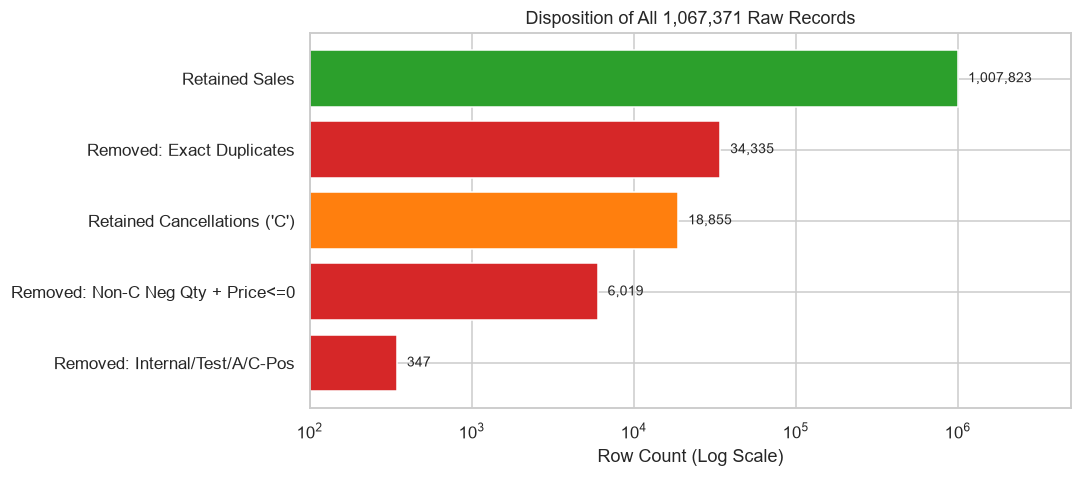

In [3]:
inv = typed_df["invoice"]
sc = typed_df["stock_code"]
qty = typed_df["quantity"]
price = typed_df["price"]

is_c = inv.str.startswith("C", na=False)
is_a = inv.str.startswith("A", na=False)
is_test = sc.str.startswith("TEST", na=False)
is_non_c_neg = (qty < 0) & (~is_c)
is_c_pos = (qty > 0) & is_c
is_price_le_zero = price <= 0
is_internal_code = sc.isin(INTERNAL_NON_COMMERCIAL_CODES)
is_service_code = sc.isin(SERVICE_OR_FEE_CODES)

category_audit = pd.DataFrame([
    ("A-prefixed bad-debt accounting adjustments (Price < 0 or > 0)", int(is_a.sum()), "Excluded (non-customer ledger entry)"),
    ("TEST* internal software test codes", int(is_test.sum()), "Excluded (non-commercial test data)"),
    ("Non-C negative-quantity warehouse write-offs (Price == 0, no Customer ID)", int(is_non_c_neg.sum()), "Excluded (inventory damage/loss note)"),
    ("Zero/negative Price rows (all post-dedup Price <= 0)", int(is_price_le_zero.sum()), "Excluded (unpriced/bad-debt; removes all missing Descriptions)"),
    ("Anomalous C-invoice with positive Quantity (C496350)", int(is_c_pos.sum()), "Excluded (contradictory sign on manual C-invoice)"),
    ("Internal platform/bank/sample codes (AMAZONFEE, BANK CHARGES, ADJUST, CRUK, S)", int(is_internal_code.sum()), "Excluded (non-customer business expenses/samples)"),
    ("Valid C-prefixed cancellations & returns (Quantity < 0, Price > 0)", int((is_c & (qty < 0) & (price > 0) & (~is_internal_code) & (~is_test)).sum()), "Retained (saved in cleaned & returns_and_cancellations)"),
    ("Customer-facing fee/service/manual codes (POST, DOT, C2, D, M) in valid rows", int((is_service_code & (price > 0) & (~is_c_pos) & (~is_a)).sum()), "Retained & flagged (is_merchandise=False)"),
], columns=["Category (Post-Deduplication)", "Row Count", "Cleaning Decision"])
display(category_audit)

# Visual comparison of retained vs removed records
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_counts = pd.Series({
    "Retained Sales": int(((~is_c) & (qty > 0) & (price > 0) & (~is_a) & (~is_test) & (~is_internal_code)).sum()),
    "Retained Cancellations ('C')": int((is_c & (qty < 0) & (price > 0) & (~is_test) & (~is_internal_code)).sum()),
    "Removed: Exact Duplicates": dup_count,
    "Removed: Non-C Neg Qty + Price<=0": int((is_price_le_zero | is_non_c_neg).sum()),
    "Removed: Internal/Test/A/C-Pos": int((is_a | is_test | is_c_pos | (is_internal_code & (price > 0))).sum()),
}).sort_values()
colors = ["#d62728" if k.startswith("Removed") else ("#ff7f0e" if "Cancellations" in k else "#2ca02c") for k in plot_counts.index]
bars = ax.barh(plot_counts.index, plot_counts.values, color=colors)
ax.set_xscale("log")
ax.set_xlabel("Row Count (Log Scale)")
ax.set_title("Disposition of All 1,067,371 Raw Records")
for bar, val in zip(bars, plot_counts.values):
    ax.text(val * 1.15, bar.get_y() + bar.get_height() / 2, f"{val:,}", va="center", fontsize=9)
ax.set_xlim(100, plot_counts.max() * 5)
plt.tight_layout()
plt.show()

### Distinguishing Negative Values, Cancellations, and Operational Noise
- **Not all negative records mean the same thing:**
  1. **`C`-prefixed cancellations (`18,855` valid rows):** Real customer order reversals/returns with positive unit prices (`Price > 0`) and negative quantities (`Quantity < 0`). These **must be retained** (and cleanly separated/flagged) so net customer spend and return behavior remain accurate.
  2. **Non-`C` negative quantities (`3,393` post-dedup rows):** Warehouse stock write-offs (`damages`, `lost`, `short`, or missing descriptions) that all have `Price == 0.0` and missing `customer_id`. Removing these prevents internal warehouse shrinkage from distorting customer analytics.
  3. **`A`-prefixed bad-debt entries (`6` rows, including all `5` negative-price rows):** Ledger write-offs (`Adjust bad debt`, `StockCode='B'`), excluded as non-customer accounting entries.
  4. **Internal fees & test records (`323` internal fee/sample rows + `17` `TEST*` rows + `1` contradictory positive-quantity `C`-row `C496350`):** Excluded so platform fees like `AMAZONFEE` (`-£221,520.50`) or `BANK CHARGES` do not masquerade as retail product transactions.
- **Handling Missing Descriptions Transparently:** Once `Price <= 0` rows (`6,019` post-dedup rows: `5` negative + `6,014` zero) are excluded, **`0` missing `description` values remain**—meaning zero descriptions had to be imputed or fabricated!

Step-by-step Cleaning Audit Log:


,step,rows_before,rows_removed,rows_after,reason
0,Remove exact duplicate rows,1067371,34335,1033036,Eliminates combined-sheet overlap duplicates (...
1,Remove 'A'-prefixed bad-debt adjustments,1033036,6,1033030,Internal ledger bad-debt adjustments (includes...
2,Remove TEST* stock codes,1033030,17,1033013,Internal software test product entries (TEST00...
3,Remove non-C negative-quantity write-offs,1033013,3393,1029620,Warehouse inventory adjustments (damages/lost/...
4,Remove Price <= 0 records,1029620,2618,1027002,Unpriced adjustments/promos (also resolves 100...
5,Remove anomalous C-invoice with Quantity > 0,1027002,1,1027001,Single contradictory manual cancellation row (...
6,Remove internal fee/ledger/sample StockCodes,1027001,323,1026678,"Excludes AMAZONFEE, BANK CHARGES, ADJUST, ADJU..."



Original rows: 1,067,371
Total rows removed across all steps: 40,693 (3.81%)
Final cleaned rows retained: 1,026,678 (96.19%)


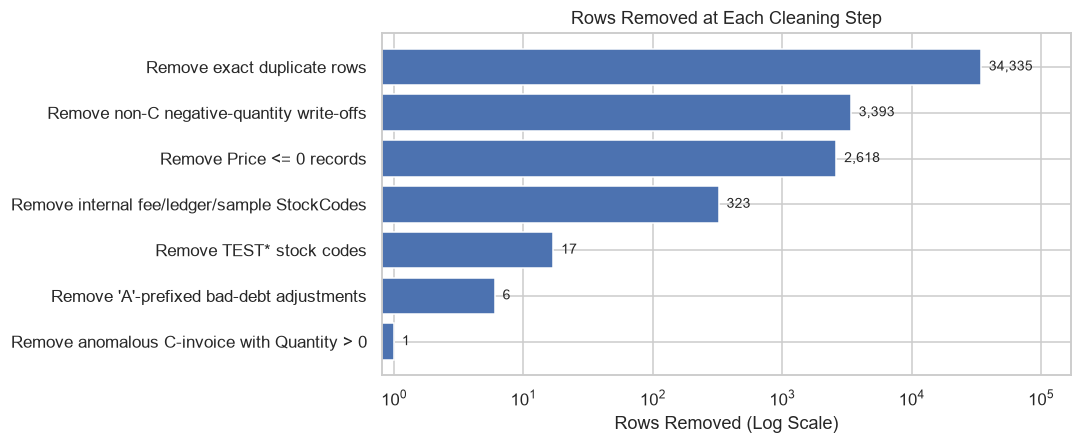

In [4]:
cleaned_df, audit_log_df = clean_retail_transactions(raw_df)
print("Step-by-step Cleaning Audit Log:")
display(audit_log_df)

total_removed = int(audit_log_df["rows_removed"].sum())
print(f"\nOriginal rows: {len(raw_df):,}")
print(f"Total rows removed across all steps: {total_removed:,} ({total_removed / len(raw_df) * 100:.2f}%)")
print(f"Final cleaned rows retained: {len(cleaned_df):,} ({len(cleaned_df) / len(raw_df) * 100:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 4.2))
steps_nonzero = audit_log_df.set_index("step")["rows_removed"].sort_values()
bars = ax.barh(steps_nonzero.index, steps_nonzero.values, color="#4c72b0")
ax.set_xscale("log")
ax.set_xlabel("Rows Removed (Log Scale)")
ax.set_title("Rows Removed at Each Cleaning Step")
for bar, val in zip(bars, steps_nonzero.values):
    ax.text(val * 1.15, bar.get_y() + bar.get_height() / 2, f"{val:,}", va="center", fontsize=9)
ax.set_xlim(0.8, steps_nonzero.max() * 5)
plt.tight_layout()
plt.show()

### Step-by-Step Audit Log Analysis
- Every single removed record is accounted for across 7 transparent steps totaling **40,693 removed rows (`3.81%`)**, leaving **1,026,678 validated commercial transaction rows (`96.19%`)**.
- Notice how **84.4%** of all removed rows (`34,335` of `40,693`) were exact duplicates rather than lost unique transactions.

In [5]:
sales_df, returns_df = split_sales_and_returns(cleaned_df)

# 1. Exact partition check
assert len(sales_df) + len(returns_df) == len(cleaned_df)
# 2. Sign & amount validations
assert (sales_df["quantity"] > 0).all() and (sales_df["price"] > 0).all() and (sales_df["transaction_amount"] > 0).all()
assert (returns_df["quantity"] < 0).all() and (returns_df["price"] > 0).all() and (returns_df["transaction_amount"] < 0).all()
assert returns_df["invoice"].str.startswith("C").all()
assert int(cleaned_df.duplicated().sum()) == 0
# 3. Verify transaction_amount == round(quantity * price, 4)
max_amount_diff = float((cleaned_df["transaction_amount"] - (cleaned_df["quantity"] * cleaned_df["price"]).round(4)).abs().max())
assert max_amount_diff == 0.0

validation_summary = pd.DataFrame({
    "dtype": cleaned_df.dtypes.astype(str),
    "missing_count": cleaned_df.isna().sum(),
    "missing_pct": (cleaned_df.isna().mean() * 100).round(4),
})
print("Post-Cleaning Schema & Missing Values Check:")
display(validation_summary)

scope_summary = pd.DataFrame([
    ("All Valid Transactions (cleaned_online_retail)", len(cleaned_df), int(cleaned_df["has_customer_id"].sum()), int((~cleaned_df["has_customer_id"]).sum()), round(float(cleaned_df["transaction_amount"].sum()), 2)),
    ("Normal Sales Only (sales_transactions)", len(sales_df), int(sales_df["has_customer_id"].sum()), int((~sales_df["has_customer_id"]).sum()), round(float(sales_df["transaction_amount"].sum()), 2)),
    ("Returns & Cancellations (returns_and_cancellations)", len(returns_df), int(returns_df["has_customer_id"].sum()), int((~returns_df["has_customer_id"]).sum()), round(float(returns_df["transaction_amount"].sum()), 2)),
], columns=["Dataset", "Rows", "With Customer ID", "Missing Customer ID", "Total Transaction Amount (£)"])
display(scope_summary)

print(f"Max transaction_amount calculation error: {max_amount_diff}")
print(f"Merchandise rows (is_merchandise=True): {int(cleaned_df['is_merchandise'].sum()):,}")
print(f"Service/Fee rows (POST, DOT, C2, D, M): {int((~cleaned_df['is_merchandise']).sum()):,}")
print(f"Unspecified country rows (flagged, retained): {int(cleaned_df['is_unspecified_country'].sum()):,}")

Post-Cleaning Schema & Missing Values Check:


,dtype,missing_count,missing_pct
invoice,string,0,0.0000
stock_code,string,0,0.0000
description,string,0,0.0000
quantity,int64,0,0.0000
invoice_date,datetime64[us],0,0.0000
price,float64,0,0.0000
customer_id,Int64,228994,22.3044
country,string,0,0.0000
transaction_amount,float64,0,0.0000
is_cancelled,bool,0,0.0000


,Dataset,Rows,With Customer ID,Missing Customer ID,Total Transaction Amount (£)
0,All Valid Transactions (cleaned_online_retail),1026678,797684,228994,19265931.71
1,Normal Sales Only (sales_transactions),1007823,779349,228474,20434219.52
2,Returns & Cancellations (returns_and_cancellat...,18855,18335,520,-1168287.81


Max transaction_amount calculation error: 0.0
Merchandise rows (is_merchandise=True): 1,021,350
Service/Fee rows (POST, DOT, C2, D, M): 5,328
Unspecified country rows (flagged, retained): 751


### Validation Checks Summary
- **Missing Values:** `13` of `14` columns have **0 missing values** (`description` is 100% populated!). Only `customer_id` has missing values (**`228,994` rows / `22.30%`**), preserved transparently without fabricating customer identities and indexed via `has_customer_id`.
- **Calculated Transaction Amounts:** Verified `transaction_amount == round(quantity * price, 4)` with **`0.0` discrepancy** across all `1,026,678` rows:
  - **Normal Sales (`1,007,823` rows):** Gross positive revenue of **`£20,434,219.52`** (`779,349` rows with `customer_id`, `228,474` guest rows).
  - **Returns & Cancellations (`18,855` rows):** Negative reversal amount of **`-£1,168,287.81`** (`18,335` rows with `customer_id`, `520` guest rows).
  - **All Valid Transactions Combined (`1,026,678` rows):** Net revenue of **`£19,265,931.71`** (`£16,294,622.05` across the `797,684` customer-identified rows / `5,921` unique customers).

In [6]:
PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
exported_paths = export_processed_datasets(cleaned_df, sales_df, returns_df, PROCESSED_DIR)

for name, path in exported_paths.items():
    size_mb = path.stat().st_size / (1024 * 1024)
    reloaded = pd.read_csv(path, nrows=5, dtype={"invoice": "string", "stock_code": "string"})
    print(f"Saved {path.relative_to(PROJECT_ROOT)} ({size_mb:.2f} MB) | Verified header columns: {len(reloaded.columns)}")

# Confirm raw original CSV remains 100% unchanged
raw_hash_after = sha256_file(RAW_CSV_PATH)
raw_size_after = RAW_CSV_PATH.stat().st_size
assert raw_hash_before == raw_hash_after and raw_size_before == raw_size_after
print(f"\nRaw file integrity verified (unchanged SHA-256): {raw_hash_after}")

# Write beginner-friendly cleaning summary report
report_path = PROJECT_ROOT / "reports" / "data_cleaning_report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)

sales_total = float(sales_df["transaction_amount"].sum())
returns_total = float(returns_df["transaction_amount"].sum())
net_total = float(cleaned_df["transaction_amount"].sum())
cust_net_total = float(cleaned_df.loc[cleaned_df["has_customer_id"], "transaction_amount"].sum())

md_report = [
    "# Data Cleaning & Preprocessing Report — UCI Online Retail II",
    "",
    f"- **Source Dataset (Preserved Untouched):** `{RAW_CSV_PATH.relative_to(PROJECT_ROOT)}` (SHA-256 `{raw_hash_after}`)",
    f"- **Cleaned Rows Retained:** `{len(cleaned_df):,}` of `{len(raw_df):,}` raw rows (`{len(cleaned_df)/len(raw_df)*100:.2f}%`)",
    f"- **Rows Removed:** `{total_removed:,}` (`{total_removed/len(raw_df)*100:.2f}%`)",
    "",
    "## 1. Summary of Processed Output Files (`dataset/processed/`)",
    "",
    "| File | Definition | Row Count | Customer-ID Rows | Net Amount (£) |",
    "|---|---|---:|---:|---:|",
    f"| `cleaned_online_retail.csv` | All valid commercial transactions (normal sales + `C`-prefixed returns/cancellations) | {len(cleaned_df):,} | {int(cleaned_df['has_customer_id'].sum()):,} | £{net_total:,.2f} |",
    f"| `sales_transactions.csv` | Normal positive sales (`is_cancelled == False`, `quantity > 0`, `price > 0`) | {len(sales_df):,} | {int(sales_df['has_customer_id'].sum()):,} | £{sales_total:,.2f} |",
    f"| `returns_and_cancellations.csv` | Valid `C`-prefixed cancellations/returns (`is_cancelled == True`, `quantity < 0`, `price > 0`) | {len(returns_df):,} | {int(returns_df['has_customer_id'].sum()):,} | £{returns_total:,.2f} |",
    "",
    "## 2. Step-by-Step Cleaning Audit Trail",
    "",
    "| Step | Rows Before | Rows Removed | Rows After | Why This Decision Was Made (Beginner Explanation) |",
    "|---|---:|---:|---:|---|",
]
for _, r in audit_log_df.iterrows():
    md_report.append(
        f"| {r['step']} | {int(r['rows_before']):,} | {int(r['rows_removed']):,} | {int(r['rows_after']):,} | {r['reason']} |"
    )

md_report.extend([
    "",
    "## 3. Key Cleaning & Modeling Decisions Explained",
    "",
    "1. **Standardized Column Names (`snake_case`):** Renamed `Invoice`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `Price`, `Customer ID`, and `Country` to `invoice`, `stock_code`, `description`, `quantity`, `invoice_date`, `price`, `customer_id`, and `country` so code is clean and consistent.",
    f"2. **Removed Exact Duplicates (`{dup_count:,}` rows):** Stacking the 2009–2010 and 2010–2011 sheets caused `22,844` overlapping duplicate rows in Dec 1–9, 2010, plus `11,491` repeated identical rows elsewhere. Dropping exact duplicates prevents double-counting revenue.",
    "3. **Kept Customer Returns/Cancellations Instead of Deleting All Negatives:** Valid `C`-prefixed invoices (`18,855` rows, `-£1,168,287.81`) represent real cancelled orders and returns. They are saved in both `cleaned_online_retail.csv` (flagged `is_cancelled=True`) and `returns_and_cancellations.csv` so net customer spend stays accurate.",
    "4. **Removed Non-Customer Negative & Unpriced Operational Noise:** Non-`C` negative-quantity rows (`3,393` rows) all had `price == 0` and missing `customer_id` (damaged/lost stock write-offs). `A`-prefixed invoices (`6` rows) were bad-debt ledger adjustments (including all `5` negative prices). Excluding these plus `17` `TEST*` rows, `2,618` zero-price positive rows, `1` contradictory positive `C`-row (`C496350`), and `323` internal fee/sample rows (`AMAZONFEE`, `BANK CHARGES`, `ADJUST`, `ADJUST2`, `CRUK`, `S`) ensures every remaining row is a real customer-facing transaction—and automatically eliminates **100% of missing `description` values**.",
    f"5. **Preserved Missing `Customer ID` Honestly (`{int((~cleaned_df['has_customer_id']).sum()):,}` rows):** We did not invent customer IDs. Valid guest checkouts are kept in `cleaned_online_retail.csv` for store-wide revenue/product reporting (`has_customer_id == False`), while customer-level modeling (RFM, clustering, churn, CLV) filters strictly to `has_customer_id == True` (`{int(cleaned_df['has_customer_id'].sum()):,}` rows across `{cleaned_df['customer_id'].nunique(dropna=True):,}` unique customers, £{cust_net_total:,.2f} net revenue).",
    f"6. **Added Transparency Flags:** `transaction_amount` (`quantity * price`), `is_cancelled`, `transaction_type`, `has_customer_id`, `is_merchandise` (`False` for `5,328` customer postage/carriage/discount/manual rows: `POST`, `DOT`, `C2`, `D`, `M`), and `is_unspecified_country` (`{int(cleaned_df['is_unspecified_country'].sum()):,}` rows).",
    "",
    "## 4. Final Validation Checks",
    "",
    "- **Post-cleaning exact duplicates:** `0`",
    "- **Missing values in non-ID columns:** `0` (including `0` missing `description`, `0` invalid dates, `0` invalid quantities/prices)",
    f"- **Unique customers (non-null):** `{cleaned_df['customer_id'].nunique(dropna=True):,}` (`{sales_df['customer_id'].nunique(dropna=True):,}` with sales, `{returns_df['customer_id'].nunique(dropna=True):,}` with returns)",
    f"- **Unique StockCodes (normalized):** `{cleaned_df['stock_code'].nunique():,}` (`{int(cleaned_df['is_merchandise'].sum()):,}` merchandise rows, `{int((~cleaned_df['is_merchandise']).sum()):,}` customer service/fee rows)",
    f"- **Raw CSV Integrity:** Confirmed `dataset/Ecommerce.csv` SHA-256 checksum remained identical before and after processing.",
])

report_path.write_text("\n".join(md_report) + "\n", encoding="utf-8")
print(f"Saved cleaning summary report: {report_path.relative_to(PROJECT_ROOT)}")

Saved dataset\processed\cleaned_online_retail.csv (118.30 MB) | Verified header columns: 14
Saved dataset\processed\sales_transactions.csv (115.79 MB) | Verified header columns: 14
Saved dataset\processed\returns_and_cancellations.csv (2.52 MB) | Verified header columns: 14

Raw file integrity verified (unchanged SHA-256): 32569a66f3842a82b0d8c4d63b263c5d98a76bde5d1f65c6c01bf457e541d3a9
Saved cleaning summary report: reports\data_cleaning_report.md


### Q&A
- **How were raw records cleaned without losing business meaning?** Starting from **1,067,371 raw rows**, exact duplicates (`34,335` rows) and non-customer operational noise (`6` `A`-invoices, `17` `TEST*` rows, `3,393` non-`C` warehouse write-offs, `2,618` remaining `Price <= 0` rows, `1` contradictory positive `C`-row `C496350`, and `323` internal fee/sample codes) were removed—retaining **1,026,678 validated transactions (`96.19%`)**.
- **How are normal sales, cancellations, and missing Customer IDs separated?** `cleaned_online_retail.csv` contains all **1,026,678** valid transactions and partitions cleanly into `sales_transactions.csv` (**1,007,823** positive-amount sales totaling **£20,434,219.52**) and `returns_and_cancellations.csv` (**18,855** `C`-prefixed negative-amount reversals totaling **-£1,168,287.81**). Missing `customer_id` rows (**228,994**, `22.30%`) are preserved transparently via `has_customer_id=False` without fabricating IDs.

### Data Analysis Key Findings
- **Zero Post-Cleaning Ambiguity:** `0` duplicates remain, `0` missing `description` values remain, `0` failed dates remain, and `transaction_amount == round(quantity * price, 4)` holds exactly across all `1,026,678` rows (**£19,265,931.71** net revenue).
- **Customer-Level Scope Ready:** Filtering `has_customer_id == True` yields **797,684 rows** across **5,921 unique customers** (**£16,294,622.05** net revenue).
- **Merchandise vs. Service Clarity:** **1,021,350** rows represent physical merchandise/vouchers (`is_merchandise=True`), while **5,328** rows represent customer-facing postage, carriage, discounts, or manual adjustments (`POST`, `DOT`, `C2`, `D`, `M`).
- **Original Data Preserved:** Verified `dataset/Ecommerce.csv` size and SHA-256 hash remained completely unchanged, and saved `reports/data_cleaning_report.md` alongside the three CSVs in `dataset/processed/`.

### Insights or Next Steps
- Use `dataset/processed/cleaned_online_retail.csv` (filtering `is_merchandise == True` when analyzing products, and `has_customer_id == True` when modeling customers) as the single source of truth for Exploratory Data Analysis.
- Proceed to **Exploratory Data Analysis (`03_EDA.ipynb`)** to study revenue trends, seasonality, country performance, product demand, return behavior, and customer purchase frequency distributions.